In [1]:
!apt-get install unrar

!unrar x '/content/9Nov2023.rar'

!ls

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
unrar is already the newest version (1:6.1.5-1).
0 upgraded, 0 newly installed, 0 to remove and 6 not upgraded.

UNRAR 6.11 beta 1 freeware      Copyright (c) 1993-2022 Alexander Roshal


Extracting from /content/9Nov2023.rar

Creating    9Nov2023                                                  OK
Creating    9Nov2023/1PersonStaticOtherPersonMovement                 OK
Creating    9Nov2023/1PersonStaticOtherPersonMovement/P01A            OK
Extracting  9Nov2023/1PersonStaticOtherPersonMovement/P01A/A.mat           1%  2%  4%  OK 
Extracting  9Nov2023/1PersonStaticOtherPersonMovement/P01A/IQ.mat          8%  OK 
Extracting  9Nov2023/1PersonStaticOtherPersonMovement/P01A/P.mat          10% 11% 12%  OK 
Extracting  9Nov2023/1PersonStaticOtherPersonMovement/P01A/P0-RD-1A1R1.jpg      12%  OK 
Extracting  9Nov2023/1PersonStaticOtherPersonMoveme

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
import seaborn as sns
from scipy.signal import spectrogram
import pandas as pd
import pywt

In [3]:
onepstatic_magnitude_data_path = '/content/9Nov2023/1PersonStaticOtherPersonMovement/P01A/A.mat'
mdrm_magnitude_data_path = '/content/9Nov2023/2SubjectsDiagonalMovement/P01A/A.mat'
mprm_magnitude_data_path = '/content/9Nov2023/2SubjectsRandomMovement/P01A/A.mat'
empty_magnitude_data_path = '/content/9Nov2023/Empty Environment/P01A/A.mat'
spdm_magnitude_data_path = '/content/9Nov2023/SinglePersonDiagonalMovement/P01A/A.mat'
sprm_magnitude_data_path = '/content/9Nov2023/SinglePersonRandomMovement/P01A/A.mat'

In [5]:
# Loading Data
onepstatic_magnitude_data = loadmat(onepstatic_magnitude_data_path)["Data_amplitude"]
mdrm_magnitude_data = loadmat(mdrm_magnitude_data_path)["Data_amplitude"]
mprm_magnitude_data = loadmat(mprm_magnitude_data_path)["Data_amplitude"]
empty_magnitude_data = loadmat(empty_magnitude_data_path)["Data_amplitude"]
spdm_magnitude_data = loadmat(spdm_magnitude_data_path)["Data_amplitude"]
sprm_magnitude_data = loadmat(sprm_magnitude_data_path)["Data_amplitude"]

In [9]:
df1 = pd.DataFrame(onepstatic_magnitude_data)
df1['label'] = '1PersonStaticOtherPersonMoving'

In [15]:
df2 = pd.DataFrame(mdrm_magnitude_data)
df2['label'] = '2SubjectsDiagonalMovement'

In [16]:
df3 = pd.DataFrame(mprm_magnitude_data)
df3['label'] = '2SubjectsRandomMovement'

In [17]:
df4 = pd.DataFrame(empty_magnitude_data)
df4['label'] = 'Empty Environment'

In [18]:
df5 = pd.DataFrame(spdm_magnitude_data)
df5['label'] = 'SinglePersonDiagonalMovement'

In [19]:
df6 = pd.DataFrame(sprm_magnitude_data)
df6['label'] = 'SinglePersonRandomMovement'

In [21]:
final_df = pd.concat([df1, df2, df3, df4, df5, df6], ignore_index=True)

In [23]:
final_df.head()

,0,1,2,3,4,5,6,7,8,9,...,82,83,84,85,86,87,88,89,90,label
0,0.004898,0.008237,0.012028,0.014168,0.011372,0.005713,0.003174,0.003867,0.004071,0.002954,...,0.000206,0.000580,0.000580,0.000358,0.000154,0.000207,0.000356,0.000467,0.000460,1PersonStaticOtherPersonMoving
1,0.003948,0.005513,0.008274,0.011306,0.010056,0.003982,0.001493,0.004061,0.004233,0.002847,...,0.000383,0.000620,0.000544,0.000294,0.000130,0.000206,0.000378,0.000489,0.000473,1PersonStaticOtherPersonMoving
2,0.003669,0.002967,0.002109,0.008461,0.009240,0.004164,0.003747,0.005474,0.005025,0.003244,...,0.000155,0.000417,0.000459,0.000298,0.000146,0.000252,0.000520,0.000634,0.000509,1PersonStaticOtherPersonMoving
3,0.003531,0.005495,0.009053,0.012938,0.011312,0.005280,0.002705,0.003820,0.004430,0.003280,...,0.000347,0.000682,0.000645,0.000406,0.000220,0.000351,0.000620,0.000712,0.000567,1PersonStaticOtherPersonMoving
4,0.002760,0.006472,0.012163,0.015500,0.012925,0.005434,0.001342,0.003072,0.002784,0.001580,...,0.000447,0.000702,0.000655,0.000430,0.000271,0.000396,0.000597,0.000580,0.000403,1PersonStaticOtherPersonMoving


In [24]:
# Save the DataFrame to a CSV file
final_df.to_csv('radar_9nov.csv', index=False)

In [26]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import pandas as pd

# Assuming final_df is your DataFrame
X = final_df.drop('label', axis=1)  # Features
y = final_df['label']               # Target variable

# It's a good practice to scale your data for SVM
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

# Initialize the Support Vector Classifier
svm_model = SVC(kernel='linear', random_state=42)  # You can change the kernel based on your data

# Train the model
svm_model.fit(X_train, y_train)

# Predict on test data
y_pred = svm_model.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")



Accuracy: 0.8714785490701529


<ipython-input-27-af7b26707a92>:10: FutureWarning: Support for multi-dimensional indexing (e.g. `obj[:, None]`) is deprecated and will be removed in a future version.  Convert to a numpy array before indexing instead.
  cmn = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]


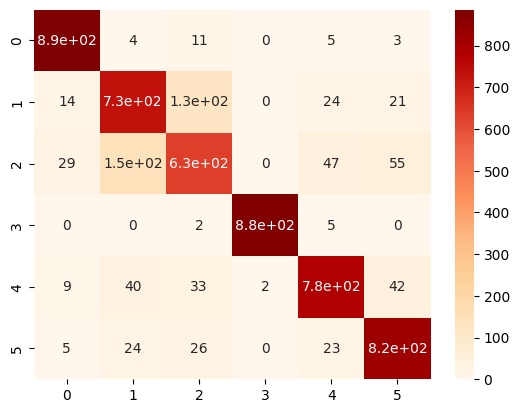

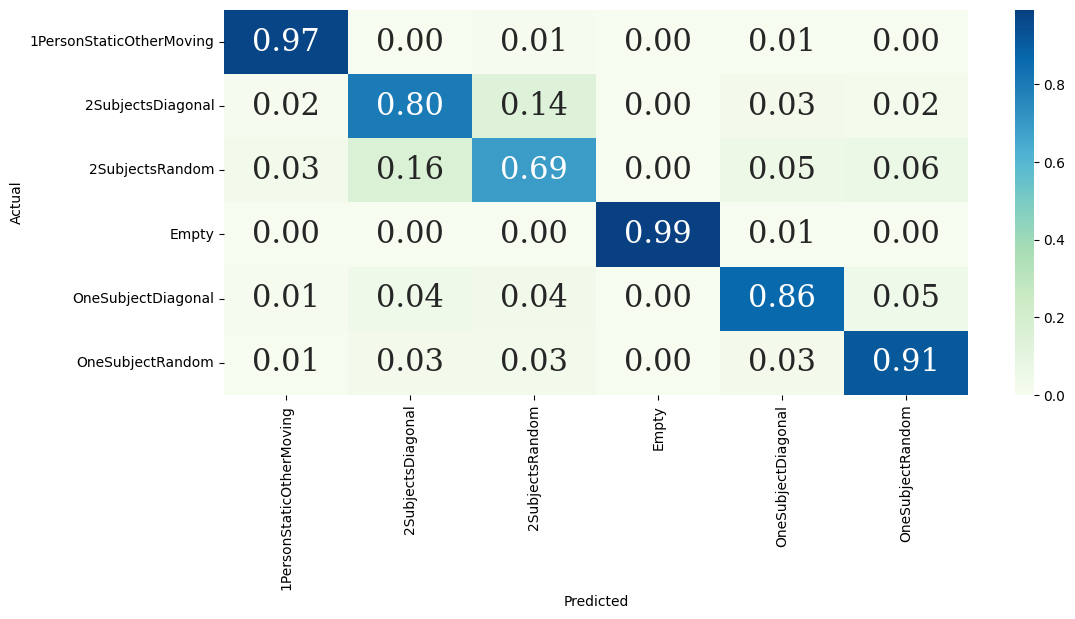

In [27]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import numpy as np
from matplotlib import pyplot as plt

targetnames = ["1PersonStaticOtherMoving", "2SubjectsDiagonal", "2SubjectsRandom", "Empty", "OneSubjectDiagonal", "OneSubjectRandom"]
cm = pd.DataFrame(confusion_matrix(y_test, y_pred))
sns.heatmap(cm, annot=True,cmap="OrRd")

cmn = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
fig, ax = plt.subplots(figsize=(12,5))
plot = sns.heatmap(cmn, annot=True, fmt='.2f', xticklabels=targetnames, yticklabels=targetnames,cmap="GnBu",annot_kws={
                'fontsize': 22, #14.5
                'fontfamily': 'serif'})
plot.figure.savefig("SVM.png",bbox_inches='tight')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()